# Assignment 3 — Part A: Sanjeevani Diagnostics — Who Gets the Blood Test?
**K-Nearest Neighbours classification.** Run the notebook top to bottom in Google Colab (*Runtime → Run all*).
The first cell asks you to upload `sanjeevani_diabetes_screening_raw.csv` if it is not already in the Colab session.
Every imputer, scaler and encoder sits inside a `Pipeline`; `random_state = 42` everywhere.

In [1]:
# Setup — imports and data upload
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import make_column_transformer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
RS = 42
FILE = 'sanjeevani_diabetes_screening_raw.csv'

if not os.path.exists(FILE):
    try:
        from google.colab import files
        print(f'Upload {FILE}')
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'Put {FILE} next to this notebook')

## Cleaning (Q1–Q6)
### Q1 — Load everything as text

In [2]:
# Q1 — load every column as text, look at the raw mess
raw = pd.read_csv(FILE, dtype=str, keep_default_na=False)
print('Shape:', raw.shape)
print('\nRaw column names (repr shows hidden spaces):')
for c in raw.columns:
    print('  ', repr(c))
for c in ['Sex', 'family_history', 'HbA1c Result ']:
    print(f'\nDistinct values of {c!r}:')
    print(raw[c].value_counts().to_dict())

Shape: (3038, 13)

Raw column names (repr shows hidden spaces):
   'Patient ID'
   'Camp Location'
   'Sex'
   'Age'
   'family_history'
   'height_cm'
   'weight_kg'
   'BMI'
   'waist_cm'
   'Daily Steps'
   'Blood Pressure'
   'total_cholesterol'
   'HbA1c Result '

Distinct values of 'Sex':
{'Male': 1144, 'Female': 1112, 'female': 147, 'F': 133, 'MALE': 131, 'FEMALE': 129, 'M': 124, 'male': 118}

Distinct values of 'family_history':
{'N': 530, 'No': 511, '0': 499, 'no': 478, 'Y': 277, '1': 257, 'yes': 248, 'Yes': 238}

Distinct values of 'HbA1c Result ':
{'0': 614, 'Negative': 606, 'No': 580, 'normal': 553, 'DIABETIC': 187, 'Positive': 173, 'Yes': 164, '1': 161}


**Interpretation:** the target column is literally `'HbA1c Result '` (trailing space), and Sex / family_history / HbA1c each use 4–8 spellings for just two real values, so they must be normalised before any model can use them.

### Q2 — Column names, missing-value markers, Camp Location and Sex

In [3]:
# Q2 — standardise column names, turn hidden missing markers into NaN, clean Camp Location and Sex
df = raw.copy()
df.columns = (df.columns.str.strip().str.lower()
                .str.replace(r'[^a-z0-9]+', '_', regex=True).str.strip('_'))
print('Clean column names:', list(df.columns))

NA_TOKENS = {'', 'na', 'n/a', 'nan', 'none', '?', 'not measured'}
df = df.apply(lambda s: s.str.strip())
df = df.mask(df.apply(lambda s: s.str.lower().isin(NA_TOKENS)))   # NA, ?, "not measured", blank -> NaN

df['camp_location'] = df['camp_location'].str.split().str.join(' ').str.title()
df['sex'] = df['sex'].str.lower().str[0].map({'m': 'Male', 'f': 'Female'})

print('\nCamp Location:', df['camp_location'].value_counts(dropna=False).to_dict())
print('Sex          :', df['sex'].value_counts(dropna=False).to_dict())

Clean column names: ['patient_id', 'camp_location', 'sex', 'age', 'family_history', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'daily_steps', 'blood_pressure', 'total_cholesterol', 'hba1c_result']

Camp Location: {'Panvel': 554, 'Kharghar': 522, 'Dombivli': 500, 'Vashi': 498, 'Nerul': 491, 'Thane': 473}
Sex          : {'Female': 1521, 'Male': 1517}


**Interpretation:** after stripping spaces and fixing case there are exactly six camps and two sexes — one spelling per category.

### Q3 — 0/1 encoding and duplicates

In [4]:
# Q3 — family_history and HbA1c Result -> 0/1, positive share, exact duplicates
YES = {'yes', 'y', '1', '1.0', 'true', 'positive', 'diabetic'}
NO  = {'no', 'n', '0', '0.0', 'false', 'negative', 'normal'}

def to01(s):
    low = s.str.lower()
    out = pd.Series(np.nan, index=s.index)
    out[low.isin(YES)] = 1
    out[low.isin(NO)] = 0
    unmapped = s[out.isna() & s.notna()].unique()
    if len(unmapped):
        print('  unmapped values in', s.name, '->', unmapped)
    return out

df['family_history'] = to01(df['family_history'])
df['hba1c_result']   = to01(df['hba1c_result'])
print('family_history:', df['family_history'].value_counts(dropna=False).to_dict())
print('hba1c_result  :', df['hba1c_result'].value_counts(dropna=False).to_dict())
print(f'Share positive (raw export, incl. duplicates): {df["hba1c_result"].mean():.1%}')

n_before = len(df)
n_dups = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
df = df[df['hba1c_result'].notna()].reset_index(drop=True)
df['hba1c_result'] = df['hba1c_result'].astype(int)
print(f'\nRows before: {n_before} | exact duplicate rows: {n_dups} | rows after: {len(df)}')
print('Patient IDs still duplicated:', df['patient_id'].duplicated().sum())
print(f'Share of visitors who tested positive: {df["hba1c_result"].mean():.1%}')

family_history: {0.0: 2018, 1.0: 1020}
hba1c_result  : {0.0: 2353, 1.0: 685}
Share positive (raw export, incl. duplicates): 22.5%

Rows before: 3038 | exact duplicate rows: 38 | rows after: 3000
Patient IDs still duplicated: 0
Share of visitors who tested positive: 22.6%


**Interpretation:** about one visitor in five is diabetic, so the classes are imbalanced — "accuracy" alone will flatter a lazy model. The 38 double-exported rows are gone, leaving one row per person.

### Q4 — Blood pressure and numeric columns

In [5]:
# Q4 — split Blood Pressure, convert Daily Steps and other numeric columns
bp = df['blood_pressure'].str.extract(r'^(\d{2,3})\s*/\s*(\d{2,3})$').astype(float)
df['systolic'], df['diastolic'] = bp[0], bp[1]
print('BP strings that could not be split:',
      df.loc[df['blood_pressure'].notna() & bp[0].isna(), 'blood_pressure'].unique())

df['daily_steps'] = df['daily_steps'].str.replace(',', '', regex=False)      # "6,540" -> "6540"
for c in ['age', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'daily_steps', 'total_cholesterol']:
    conv = pd.to_numeric(df[c], errors='coerce')
    bad = df.loc[df[c].notna() & conv.isna(), c].unique()
    if len(bad):
        print(f'{c}: non-numeric values set to NaN -> {bad}')
    df[c] = conv
df = df.drop(columns='blood_pressure')
print(df.dtypes)
display(df.head())

BP strings that could not be split: []
patient_id            object
camp_location         object
sex                   object
age                    int64
family_history       float64
height_cm            float64
weight_kg            float64
bmi                  float64
waist_cm             float64
daily_steps          float64
total_cholesterol    float64
hba1c_result           int32
systolic             float64
diastolic            float64
dtype: object


,patient_id,camp_location,sex,age,family_history,height_cm,weight_kg,bmi,waist_cm,daily_steps,total_cholesterol,hba1c_result,systolic,diastolic
0,SD-21118,Thane,Female,42,0.0,152.0,59.3,25.7,NaN,8750.0,188.0,0,102.0,69.0
1,SD-21469,Vashi,Male,27,0.0,157.0,56.9,23.0,NaN,12930.0,160.0,0,106.0,73.0
2,SD-22210,Kharghar,Male,55,0.0,175.0,48.9,16.0,78.0,6440.0,146.0,0,136.0,98.0
3,SD-20253,Dombivli,Female,54,1.0,163.0,78.9,29.9,94.0,4080.0,194.0,1,114.0,90.0
4,SD-21488,Kharghar,Female,35,1.0,159.0,70.0,27.8,102.0,4890.0,241.0,0,124.0,89.0


**Interpretation:** every measurement is now a real number, and "128/84" has become two separate columns the model can measure distance on.

### Q5 — Heights in metres and missing BMI

In [6]:
# Q5 — metres -> cm, then compute the blank BMIs
in_metres = df['height_cm'] < 3
print('Heights typed in metres:', in_metres.sum())
display(df.loc[in_metres, ['patient_id', 'height_cm', 'weight_kg', 'bmi']].head())
df.loc[in_metres, 'height_cm'] *= 100

calc_bmi = df['weight_kg'] / (df['height_cm'] / 100) ** 2
print('Check: median |tablet BMI - weight/height²| =', round((df['bmi'] - calc_bmi).abs().median(), 2))

missing_bmi = df['bmi'].isna()
show_ids = df.index[missing_bmi][:3]
print(f'\nBlank BMI: {missing_bmi.sum()} rows.  BEFORE:')
display(df.loc[show_ids, ['patient_id', 'height_cm', 'weight_kg', 'bmi']])
df.loc[missing_bmi, 'bmi'] = calc_bmi[missing_bmi].round(1)
print('AFTER:')
display(df.loc[show_ids, ['patient_id', 'height_cm', 'weight_kg', 'bmi']])
print('BMI still missing (height or weight also missing):', df['bmi'].isna().sum())

Heights typed in metres: 45


,patient_id,height_cm,weight_kg,bmi
63,SD-21552,1.56,44.3,NaN
168,SD-22591,1.65,61.1,NaN
177,SD-21600,1.61,75.4,NaN
196,SD-22657,1.61,54.8,NaN
204,SD-21350,1.62,75.9,NaN


Check: median |tablet BMI - weight/height²| = 0.08

Blank BMI: 320 rows.  BEFORE:


,patient_id,height_cm,weight_kg,bmi
56,SD-22241,177.0,69.9,NaN
63,SD-21552,156.0,44.3,NaN
73,SD-22406,166.0,67.3,NaN


AFTER:


,patient_id,height_cm,weight_kg,bmi
56,SD-22241,177.0,69.9,22.3
63,SD-21552,156.0,44.3,18.2
73,SD-22406,166.0,67.3,24.4


BMI still missing (height or weight also missing): 0


**Why compute rather than median-impute?** BMI is not unknown — it is a formula of two columns we *have*. Computing it gives each person their true BMI (the check above shows it matches the tablet almost exactly), while the median would give all ~320 people the same "average" BMI, erasing exactly the signal (heavier → higher risk) that KNN uses to find similar visitors, and doing so for two whole camps at once.

### Q6 — Impossible ages and missing values

In [7]:
# Q6 — impossible ages -> NaN, missing-value report, save the cleaned file (NOT imputed)
bad_age = (df['age'] < 10) | (df['age'] > 110)
print('Impossible ages found:', df.loc[bad_age, 'age'].value_counts().to_dict())
df.loc[bad_age, 'age'] = np.nan

print('\nMissing values per column:')
print(df.isna().sum())
df.to_csv('sanjeevani_clean.csv', index=False)
print('\nSaved sanjeevani_clean.csv', df.shape)

Impossible ages found: {140: 3, 3: 2, 0: 1, 999: 1}

Missing values per column:
patient_id             0
camp_location          0
sex                    0
age                    7
family_history         0
height_cm              0
weight_kg              0
bmi                    0
waist_cm              90
daily_steps           60
total_cholesterol    150
hba1c_result           0
systolic              25
diastolic             25
dtype: int64



Saved sanjeevani_clean.csv (3000, 14)


**Imputation plan:** the remaining gaps (age, waist, cholesterol, BP, a few others) will be filled with a **median `SimpleImputer` inside the pipeline** (most-frequent for the categorical columns). Median is robust to the skew in steps and cholesterol.

**Why not impute now?** If we computed the median on all 3,000 rows, the 750 test people would help decide the fill value used for training — information from the "future" leaks into the model and the test score becomes optimistic. Inside a pipeline, the median is learned from the training folds only and merely *applied* to test rows.

## KNN by hand (Q7–Q9)
### Q7 — Raw Euclidean distance
New visitor: waist = 98 cm, steps = 6,000.  $d=\sqrt{(\Delta\text{waist})^2+(\Delta\text{steps})^2}$

* **P1** (76, 6,050): Δwaist = −22, Δsteps = 50 → √(484 + 2,500) = √2,984 = **54.63**
* **P2** (80, 5,980): Δwaist = −18, Δsteps = −20 → √(324 + 400) = √724 = **26.91**
* **P3** (101, 7,400): Δ = 3, 1,400 → √(9 + 1,960,000) = **1,400.00**
* **P4** (96, 8,000): Δ = −2, 2,000 → √(4 + 4,000,000) = **2,000.00**
* **P5** (106, 4,500): Δ = 8, −1,500 → √(64 + 2,250,000) = **1,500.02**
* **P6** (82, 6,100): Δ = −16, 100 → √(256 + 10,000) = **101.27**

k = 3 nearest: **P2 (26.9), P1 (54.6), P6 (101.3)** → all Negative → prediction **Negative**.

In [8]:
# Q7 — check the hand calculation
pts = pd.DataFrame({'waist': [76, 80, 101, 96, 106, 82],
                    'steps': [6050, 5980, 7400, 8000, 4500, 6100],
                    'result': ['Negative', 'Negative', 'Positive', 'Positive', 'Positive', 'Negative']},
                   index=['P1', 'P2', 'P3', 'P4', 'P5', 'P6'])
new = np.array([98, 6000])
pts['euclid_raw'] = np.sqrt(((pts[['waist', 'steps']] - new) ** 2).sum(axis=1)).round(2)
print(pts.sort_values('euclid_raw'))
top3 = pts.nsmallest(3, 'euclid_raw')
print('\nk=3 neighbours:', list(top3.index), '-> prediction:', top3['result'].mode()[0])

    waist  steps    result  euclid_raw
P2     80   5980  Negative       26.91
P1     76   6050  Negative       54.63
P6     82   6100  Negative      101.27
P3    101   7400  Positive     1400.00
P5    106   4500  Positive     1500.02
P4     96   8000  Positive     2000.00



k=3 neighbours: ['P2', 'P1', 'P6'] -> prediction: Negative


**Interpretation:** with raw numbers the step count (thousands) swamps waist (tens), so KNN just picks whoever walks ~6,000 steps — waist barely matters.

### Q8 — Min-max scaled Euclidean distance
Scaled waist = (w − 60)/80, scaled steps = s/20,000. New visitor → (38/80, 6,000/20,000) = **(0.475, 0.300)**.

| Visitor | scaled waist | scaled steps | Δw | Δs | distance |
|---|---|---|---|---|---|
| P1 | 0.2000 | 0.3025 | −0.2750 | 0.0025 | √(0.075625 + 0.00000625) = **0.2750** |
| P2 | 0.2500 | 0.2990 | −0.2250 | −0.0010 | √(0.050625 + 0.000001) = **0.2250** |
| P3 | 0.5125 | 0.3700 | 0.0375 | 0.0700 | √(0.00140625 + 0.0049) = **0.0794** |
| P4 | 0.4500 | 0.4000 | −0.0250 | 0.1000 | √(0.000625 + 0.01) = **0.1031** |
| P5 | 0.5750 | 0.2250 | 0.1000 | −0.0750 | √(0.01 + 0.005625) = **0.1250** |
| P6 | 0.2750 | 0.3050 | −0.2000 | 0.0050 | √(0.04 + 0.000025) = **0.2001** |

k = 3 nearest: **P3 (0.079), P4 (0.103), P5 (0.125)** → all Positive → prediction **Positive**.

**Why it flipped:** unscaled, a 1,400-step gap counted 1,400 times more than a 1 cm waist gap, so the model ignored the waist completely; after scaling each feature contributes in proportion to its share of its own realistic range. A doctor would agree with the scaled answer — a 98 cm waist with modest activity looks like P3–P5 (large waists, all diabetic), not like the slim P1/P2/P6.

In [9]:
# Q8 — check with code
lo, hi = np.array([60, 0]), np.array([140, 20000])
scaled = (pts[['waist', 'steps']] - lo) / (hi - lo)
new_s = (new - lo) / (hi - lo)
pts['euclid_scaled'] = np.sqrt(((scaled - new_s) ** 2).sum(axis=1)).round(4)
print(pts[['waist', 'steps', 'result', 'euclid_scaled']].sort_values('euclid_scaled'))
top3 = pts.nsmallest(3, 'euclid_scaled')
print('\nk=3 neighbours:', list(top3.index), '-> prediction:', top3['result'].mode()[0])

    waist  steps    result  euclid_scaled
P3    101   7400  Positive         0.0794
P4     96   8000  Positive         0.1031
P5    106   4500  Positive         0.1250
P6     82   6100  Negative         0.2001
P2     80   5980  Negative         0.2250
P1     76   6050  Negative         0.2750

k=3 neighbours: ['P3', 'P4', 'P5'] -> prediction: Positive


**Interpretation:** scaling gives waist a fair vote, and the nearest neighbours become the three large-waist diabetics.

### Q9 — Manhattan distance (scaled)
$d = |\Delta w| + |\Delta s|$

* P1: 0.2750 + 0.0025 = **0.2775**
* P2: 0.2250 + 0.0010 = **0.2260**
* P3: 0.0375 + 0.0700 = **0.1075**
* P4: 0.0250 + 0.1000 = **0.1250**
* P5: 0.1000 + 0.0750 = **0.1750**
* P6: 0.2000 + 0.0050 = **0.2050**

k = 3: **P3, P4, P5** → still **Positive**; no change (only the gaps between distances changed).

**When to prefer Manhattan:** when there are many features or noisy outliers — Manhattan adds differences linearly instead of squaring them, so one feature with a single large gap cannot dominate the distance; it also suits features that genuinely add up independently (e.g. grid-like / city-block movement).

In [10]:
# Q9 — check
pts['manhattan_scaled'] = (scaled - new_s).abs().sum(axis=1).round(4)
print(pts[['result', 'euclid_scaled', 'manhattan_scaled']].sort_values('manhattan_scaled'))
top3 = pts.nsmallest(3, 'manhattan_scaled')
print('\nk=3 neighbours:', list(top3.index), '-> prediction:', top3['result'].mode()[0])

      result  euclid_scaled  manhattan_scaled
P3  Positive         0.0794            0.1075
P4  Positive         0.1031            0.1250
P5  Positive         0.1250            0.1750
P6  Negative         0.2001            0.2050
P2  Negative         0.2250            0.2260
P1  Negative         0.2750            0.2775



k=3 neighbours: ['P3', 'P4', 'P5'] -> prediction: Positive


**Interpretation:** Euclidean and Manhattan agree here; the big lesson of Q7–Q9 is that *scaling* changed the answer, not the choice of metric.

## Building the model (Q10–Q17)
### Q10 — Stratified train/test split and a "nobody is diabetic" baseline

In [11]:
# Q10 — 75/25 stratified split
NUM = ['age', 'bmi', 'waist_cm', 'daily_steps', 'systolic', 'diastolic', 'total_cholesterol']
CAT = ['sex', 'family_history']
X = df[NUM + CAT + ['camp_location']]
y = df['hba1c_result']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RS)
yt = y_test.to_numpy()
print('Train:', X_train.shape, f'positive rate {y_train.mean():.1%}')
print('Test :', X_test.shape, f'positive rate {y_test.mean():.1%}')
baseline_acc = 1 - y_test.mean()
print(f'"Everyone negative" baseline accuracy on test: {baseline_acc:.1%}')

Train: (2250, 10) positive rate 22.6%


Test :

 (750, 10) positive rate 22.7%
"Everyone negative" baseline accuracy on test: 77.3%


**Interpretation:** stratification keeps the diabetic share the same in both halves, and a model that never finds a single diabetic already scores ~78% accuracy — the bar any real model has to clear.

### Q11 — KNN (k = 5) without scaling

In [12]:
# Q11 — unscaled KNN on the seven numeric features
def evaluate(name, model, Xte, threshold=None):
    proba = model.predict_proba(Xte)[:, 1]
    pred = model.predict(Xte) if threshold is None else (proba >= threshold).astype(int)
    top250 = np.argsort(-proba, kind='stable')[:250]
    return {'model': name,
            'accuracy': accuracy_score(yt, pred), 'precision': precision_score(yt, pred, zero_division=0),
            'recall': recall_score(yt, pred), 'f1': f1_score(yt, pred), 'roc_auc': roc_auc_score(yt, proba),
            'diabetics_in_top250': int(yt[top250].sum())}, pred, proba

def show_cm(pred):
    cm = confusion_matrix(yt, pred)
    display(pd.DataFrame(cm, index=['actual neg', 'actual pos'], columns=['pred neg', 'pred pos']))

raw_knn = make_pipeline(SimpleImputer(strategy='median'), KNeighborsClassifier(n_neighbors=5))
raw_knn.fit(X_train[NUM], y_train)
res_raw, pred_raw, proba_raw = evaluate('raw KNN (k=5, unscaled)', raw_knn, X_test[NUM])
print(pd.Series(res_raw).drop('model').round(3))
show_cm(pred_raw)
print(f'Baseline accuracy {baseline_acc:.3f} vs raw KNN accuracy {res_raw["accuracy"]:.3f}')

accuracy               0.762667
precision              0.441176
recall                 0.176471
f1                     0.252101
roc_auc                0.656364
diabetics_in_top250          81
dtype: object


,pred neg,pred pos
actual neg,542,38
actual pos,140,30


Baseline accuracy 0.773 vs raw KNN accuracy 0.763


**Interpretation:** the unscaled model barely beats (or even trails) the do-nothing baseline on accuracy and misses most diabetics — it is not really looking at the medical measurements.

### Q12 — Add a StandardScaler

In [13]:
# Q12 — same model with StandardScaler
scaled_knn = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsClassifier(n_neighbors=5))
scaled_knn.fit(X_train[NUM], y_train)
res_scaled, pred_scaled, proba_scaled = evaluate('scaled KNN (k=5)', scaled_knn, X_test[NUM])
show_cm(pred_scaled)
display(pd.DataFrame([res_raw, res_scaled]).set_index('model').round(3))

spread = X_train[NUM].std()
share = (spread ** 2 / (spread ** 2).sum()).sort_values(ascending=False)
print('Std. dev. of each feature (training set) and its share of the squared distance:')
display(pd.DataFrame({'std': spread.round(1), 'share_of_distance': share.round(4)}).sort_values('std', ascending=False))
print(f'Dominating feature in Q11: {share.index[0]} (~{share.iloc[0]:.0%} of the squared distance)')

,pred neg,pred pos
actual neg,533,47
actual pos,112,58


,accuracy,precision,recall,f1,roc_auc,diabetics_in_top250
model,,,,,,
"raw KNN (k=5, unscaled)",0.763,0.441,0.176,0.252,0.656,81
scaled KNN (k=5),0.788,0.552,0.341,0.422,0.723,99


Std. dev. of each feature (training set) and its share of the squared distance:


,std,share_of_distance
daily_steps,3107.2,0.9998
total_cholesterol,37.6,0.0001
systolic,14.1,0.0000
age,11.9,0.0000
diastolic,10.7,0.0000
waist_cm,8.1,0.0000
bmi,4.2,0.0000


Dominating feature in Q11: daily_steps (~100% of the squared distance)


**Interpretation:** daily_steps has a standard deviation in the thousands while every other feature is in single or double digits, so it made up almost all of the unscaled distance — Q11 was effectively "KNN on step count". Scaling puts all seven measurements on equal terms and every metric improves.

### Q13 — Why the scaler is fitted on training data only
The scaler learns a mean and standard deviation. If those came from the full dataset, the test visitors' values would shape how the training data is transformed — the model would have "seen" the test set, and the test score would no longer be an honest estimate for next month's camp visitors. Putting the imputer and scaler **inside a pipeline** guarantees that `fit` (on train, or on each CV training fold) learns the statistics, and `predict` on test only *applies* them.

In [14]:
# Q13 — the pipeline that guarantees no leakage
leak_free = make_pipeline(SimpleImputer(strategy='median'),   # median learned on train only
                          StandardScaler(),                   # mean / std learned on train only
                          KNeighborsClassifier(n_neighbors=5))
leak_free.fit(X_train[NUM], y_train)            # fit sees only the training rows
_ = leak_free.predict_proba(X_test[NUM])        # test rows are only transformed, never fitted

sc = leak_free.named_steps['standardscaler']
print('Scaler means = training means after imputation?',
      np.allclose(sc.mean_, SimpleImputer(strategy='median').fit_transform(X_train[NUM]).mean(axis=0)))

Scaler means = training means after imputation? True


**Interpretation:** the fitted scaler's means equal the training-set means exactly, so no test-set information went into the transformation.

### Q14 — Choosing k with 5-fold stratified cross-validation

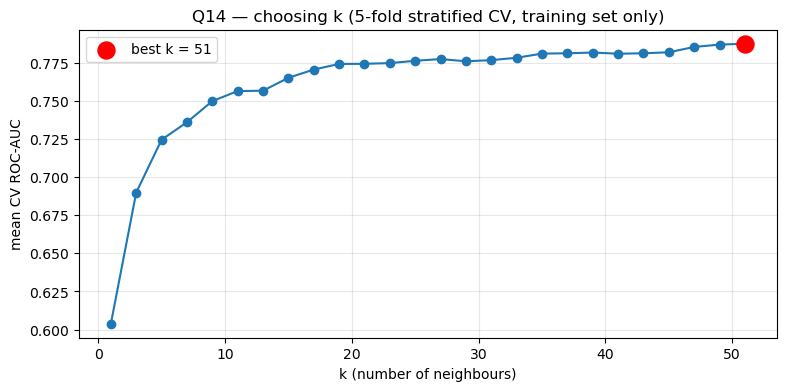

Best k = 51, CV ROC-AUC = 0.788  (k=1: 0.604, k=51: 0.788)


  k=  75: CV ROC-AUC 0.794


  k= 101: CV ROC-AUC 0.794


  k= 151: CV ROC-AUC 0.798


  k= 251: CV ROC-AUC 0.800


  k= 501: CV ROC-AUC 0.802


  k=1001: CV ROC-AUC 0.799


In [15]:
# Q14 — ROC-AUC vs k on the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
ks = list(range(1, 52, 2))
cv_auc = []
for k in ks:
    pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_auc.append(cross_val_score(pipe, X_train[NUM], y_train, cv=cv, scoring='roc_auc').mean())
best_k = ks[int(np.argmax(cv_auc))]

plt.figure(figsize=(9, 4))
plt.plot(ks, cv_auc, marker='o')
plt.scatter([best_k], [max(cv_auc)], s=150, color='red', zorder=3, label=f'best k = {best_k}')
plt.xlabel('k (number of neighbours)'); plt.ylabel('mean CV ROC-AUC')
plt.title('Q14 — choosing k (5-fold stratified CV, training set only)')
plt.grid(alpha=.3); plt.legend(); plt.show()
print(f'Best k = {best_k}, CV ROC-AUC = {max(cv_auc):.3f}  (k=1: {cv_auc[0]:.3f}, k=51: {cv_auc[-1]:.3f})')

# the curve is still flattening at 51 -> look further to see the high-bias side
for k in [75, 101, 151, 251, 501, 1001]:
    pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    print(f'  k={k:4d}: CV ROC-AUC {cross_val_score(pipe, X_train[NUM], y_train, cv=cv, scoring="roc_auc").mean():.3f}')

**Interpretation:** at **very small k** (k = 1, 3) the prediction depends on one or two neighbours, so a single odd person changes the answer — *low bias, high variance*, and AUC is poor (≈0.60 at k = 1). As k grows the vote averages out the noise and AUC climbs steeply, then flattens: within 1–51 the best value is at the top end, but the gains after k ≈ 25 are tiny. The extra check beyond 51 shows the other side: when the "neighbourhood" becomes a large slice of all 1,800 training people, scores drift towards the overall 22% rate, real local differences are smoothed away — *high bias, low variance* — and AUC stops improving and then falls. The best k sits where the two errors balance.

### Q15 — Add sex and family history, grid-search k, weights and p

In [16]:
# Q15 — ColumnTransformer + GridSearchCV
preprocess = make_column_transformer(
    (make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUM),
    (make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore')), ['sex']),
    (make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore')), ['family_history']),
)
tuned_pipe = Pipeline([('prep', preprocess), ('knn', KNeighborsClassifier())])
param_grid = {'knn__n_neighbors': list(range(1, 152, 2)), 'knn__weights': ['uniform', 'distance'], 'knn__p': [1, 2]}
grid = GridSearchCV(tuned_pipe, param_grid, scoring='roc_auc', cv=cv)
grid.fit(X_train[NUM + CAT], y_train)
best = grid.best_estimator_
print('Best parameters:', grid.best_params_)
print(f'Best CV ROC-AUC: {grid.best_score_:.3f}  (numeric-only best k in Q14: {max(cv_auc):.3f})')

Best parameters: {'knn__n_neighbors': 151, 'knn__p': 1, 'knn__weights': 'uniform'}
Best CV ROC-AUC: 0.813  (numeric-only best k in Q14: 0.788)


**Interpretation:** family history and sex add real medical information, and the search picks the k, weighting and distance metric that rank diabetics highest on unseen folds.

### Q16 — Test-set evaluation at the default 0.5 threshold

In [17]:
# Q16 — tuned model on the test set
res_tuned, pred_tuned, proba_tuned = evaluate('tuned KNN', best, X_test[NUM + CAT])
print(pd.Series(res_tuned).drop('model').round(3))
show_cm(pred_tuned)
tn, fp, fn, tp = confusion_matrix(yt, pred_tuned).ravel()
print(f'TP = {tp}: diabetics we flagged and sent for HbA1c — the ₹450 found a real case.')
print(f'FP = {fp}: non-diabetics we sent for a test that came back normal — ₹450 spent without a find.')
print(f'FN = {fn}: diabetics we sent home without a test — the costliest mistake, the disease goes undetected.')
print(f'TN = {tn}: healthy visitors we correctly did not test — money saved for someone at higher risk.')

accuracy               0.789333
precision                   0.8
recall                 0.094118
f1                     0.168421
roc_auc                0.804792
diabetics_in_top250         118
dtype: object


,pred neg,pred pos
actual neg,576,4
actual pos,154,16


TP = 16: diabetics we flagged and sent for HbA1c — the ₹450 found a real case.
FP = 4: non-diabetics we sent for a test that came back normal — ₹450 spent without a find.
FN = 154: diabetics we sent home without a test — the costliest mistake, the disease goes undetected.
TN = 576: healthy visitors we correctly did not test — money saved for someone at higher risk.


**Interpretation:** ROC-AUC shows the model ranks diabetics well, but at 0.5 it flags relatively few people, so many diabetics fall into the FN cell.

### Q17 — Why Camp Location is left out
* **For including it:** camps serve different neighbourhoods (income, diet, age mix), so the base rate of diabetes may genuinely differ by camp, and location could proxy for those unmeasured factors.
* **Against:** the model must work at *new* camps that weren't in the pilot (a one-hot "Dombivli" column means nothing for Airoli); location is a property of the camp, not the person's body, so it can learn sampling quirks (e.g. which camps had the tablet crash) instead of medicine; and it would make two physically identical people get different priority purely because of where they queued — hard to defend for a free CSR health programme.

## The budget decision (Q18–Q23)
### Q18 — Why 0.5 is the wrong cut-off

In [18]:
# Q18
print(f'Recall at 0.5: {res_tuned["recall"]:.1%}  -> only {tp} of {tp + fn} test-set diabetics are flagged; '
      f'{(pred_tuned == 1).sum()} tests ordered when the budget allows 250.')

Recall at 0.5: 9.4%  -> only 16 of 170 test-set diabetics are flagged; 20 tests ordered when the budget allows 250.


**Interpretation:** 0.5 maximises accuracy because most people are negative, but it treats a missed diabetic (FN) and a wasted ₹450 test (FP) as equally bad and leaves most of the 250-test budget unused. Missing a diabetic is far costlier than a negative test, so the cut-off should be set by the budget (or a much lower threshold), not by accuracy.

### Q19 — Threshold table

In [19]:
# Q19 — tests, finds and cost per diabetic at different thresholds
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5]:
    sel = proba_tuned >= t
    found = int(yt[sel].sum())
    rows.append({'threshold': t, 'tests_ordered': int(sel.sum()), 'diabetics_found': found,
                 'diabetics_missed': int(yt.sum() - found),
                 'hit_rate': found / sel.sum() if sel.sum() else np.nan,
                 'cost_per_diabetic_rs': 450 * sel.sum() / found if found else np.nan})
thr = pd.DataFrame(rows)
display(thr.round(3))

,threshold,tests_ordered,diabetics_found,diabetics_missed,hit_rate,cost_per_diabetic_rs
0,0.1,592,166,4,0.280,1604.819
1,0.2,333,136,34,0.408,1101.838
2,0.3,169,89,81,0.527,854.494
3,0.4,53,36,134,0.679,662.500
4,0.5,20,16,154,0.800,562.500


**Interpretation:** lowering the threshold finds more diabetics but orders more tests at a lower hit-rate; the threshold where tests ≈ 250 is the one the budget can afford.

### Q20 — Spend exactly 250 tests on the highest-risk visitors

In [20]:
# Q20 — top 250 by predicted probability
rank = np.argsort(-proba_tuned, kind='stable')
top250 = rank[:250]
found250 = int(yt[top250].sum())
cut = proba_tuned[rank[249]]
print(f'Test set: {len(yt)} people, {yt.sum()} diabetics')
print(f'Top-250 list finds {found250} diabetics ({found250 / yt.sum():.0%} of all), hit-rate {found250 / 250:.0%}, '
      f'₹{450 * 250 / found250:,.0f} per diabetic found')
print(f'Random 250 would find ≈ {0.22 * 250:.0f} -> the model finds {found250 / 55:.1f}x as many')
print(f'(Probability at the cut-off: {cut:.3f}; people tied at that value: {(proba_tuned == cut).sum()})')

Test set: 750 people, 170 diabetics
Top-250 list finds 118 diabetics (69% of all), hit-rate 47%, ₹953 per diabetic found
Random 250 would find ≈ 55 -> the model finds 2.1x as many
(Probability at the cut-off: 0.245; people tied at that value: 15)


**Interpretation:** for the same ₹1,12,500, ranking by KNN probability finds far more diabetics than random selection.

### Q21 — Compare with the camp's eyeball rule

In [21]:
# Q21 — "age 45+ and waist ≥ 90 (men) / ≥ 80 (women)"
Xt = X_test.reset_index(drop=True)
rule = ((Xt['age'] >= 45) &
        (((Xt['sex'] == 'Male') & (Xt['waist_cm'] >= 90)) | ((Xt['sex'] == 'Female') & (Xt['waist_cm'] >= 80)))).to_numpy()
n_rule, found_rule = int(rule.sum()), int(yt[rule].sum())
same_n = rank[:n_rule]
comp = pd.DataFrame([
    {'approach': 'Eyeball rule', 'tests': n_rule, 'diabetics_found': found_rule},
    {'approach': 'KNN top 250', 'tests': 250, 'diabetics_found': found250},
    {'approach': f'KNN top {n_rule} (same no. of tests as rule)', 'tests': n_rule, 'diabetics_found': int(yt[same_n].sum())},
    {'approach': 'Random 250', 'tests': 250, 'diabetics_found': 55},
])
comp['hit_rate'] = comp['diabetics_found'] / comp['tests']
comp['cost_per_diabetic_rs'] = 450 * comp['tests'] / comp['diabetics_found']
display(comp.round(3))
print('Note: visitors with a missing age or waist cannot pass the eyeball rule, so they are never tested by it.')

,approach,tests,diabetics_found,hit_rate,cost_per_diabetic_rs
0,Eyeball rule,350,118,0.337,1334.746
1,KNN top 250,250,118,0.472,953.390
2,KNN top 350 (same no. of tests as rule),350,139,0.397,1133.094
3,Random 250,250,55,0.220,2045.455


Note: visitors with a missing age or waist cannot pass the eyeball rule, so they are never tested by it.


**Interpretation:** the eyeball rule uses a different number of tests and a lower hit-rate; the KNN ranking delivers more diabetics per rupee because it combines all measurements (and family history) instead of two hard cut-offs.

### Q22 — Explaining one prediction with its neighbours

In [22]:
# Q22 — nearest training neighbours of one top-250 visitor
i = top250[0]
visitor = X_test.iloc[[i]]
print(f'Visitor (test row {i}), predicted probability {proba_tuned[i]:.2f}, actual HbA1c = {yt[i]}:')
display(visitor[NUM + CAT])

prep, knn = best.named_steps['prep'], best.named_steps['knn']
dist, idx = knn.kneighbors(prep.transform(visitor[NUM + CAT]))
neigh = X_train.iloc[idx[0]][['age', 'sex', 'bmi', 'waist_cm', 'daily_steps', 'systolic', 'total_cholesterol', 'family_history']].copy()
neigh['distance'] = dist[0].round(3)
neigh['hba1c_result'] = y_train.iloc[idx[0]].to_numpy()
print(f'The model votes with k = {len(neigh)} neighbours; the 10 closest are:')
display(neigh.head(10))
n_pos = int(neigh['hba1c_result'].sum())
print(f'{int(neigh["hba1c_result"].head(10).sum())} of the 10 closest and {n_pos} of all {len(neigh)} '
      f'neighbours were diabetic (overall rate in the pilot: {y_train.mean():.0%}).')

Visitor (test row 165), predicted probability 0.66, actual HbA1c = 1:


,age,bmi,waist_cm,daily_steps,systolic,diastolic,total_cholesterol,sex,family_history
1842,69.0,33.6,113.0,590.0,140.0,87.0,243.0,Male,1.0


The model votes with k = 151 neighbours; the 10 closest are:


,age,sex,bmi,waist_cm,daily_steps,systolic,total_cholesterol,family_history,distance,hba1c_result
956,55.0,Male,31.0,112.0,2650.0,134.0,248.0,1.0,4.097,1
2514,61.0,Male,32.6,115.0,1480.0,150.0,222.0,0.0,4.924,1
1904,64.0,Male,36.6,117.0,7090.0,138.0,235.0,1.0,4.958,1
293,66.0,Male,34.4,119.0,3280.0,134.0,214.0,0.0,5.287,1
503,66.0,Male,28.0,102.0,300.0,130.0,221.0,1.0,5.402,1
2918,59.0,Male,25.4,103.0,2090.0,140.0,238.0,1.0,5.416,0
1597,40.0,Male,35.7,105.0,2970.0,128.0,241.0,1.0,5.996,1
1944,58.0,Male,27.4,111.0,4110.0,115.0,242.0,1.0,6.071,1
2365,47.0,Male,31.7,106.0,1250.0,124.0,221.0,1.0,6.073,1
1696,60.0,Male,26.4,107.0,4270.0,138.0,204.0,1.0,6.094,1


9 of the 10 closest and 100 of all 151 neighbours were diabetic (overall rate in the pilot: 23%).


In [23]:
# Q22 — what a volunteer could say
v = visitor.iloc[0]
print(f'"Among last year\'s visitors, we looked at the {len(neigh)} people whose age, weight, waist, blood pressure, '
      f'cholesterol and activity were closest to yours, and {n_pos} of them turned out to have diabetes." '
      f'"Your measurements (age {v.age:.0f}, waist {v.waist_cm:.0f} cm, BMI {v.bmi:.1f}) put you in that group, '
      f'so the free HbA1c test is the safest way to find out for sure."')

"Among last year's visitors, we looked at the 151 people whose age, weight, waist, blood pressure, cholesterol and activity were closest to yours, and 100 of them turned out to have diabetes." "Your measurements (age 69, waist 113 cm, BMI 33.6) put you in that group, so the free HbA1c test is the safest way to find out for sure."


### Q23 — Reply to the visitor ranked 260th
*"Thank you for raising this, and I'm sorry you weren't included today. Our list doesn't look at weight alone — it compares each person with past visitors on age, waist, blood pressure, cholesterol, daily activity, BMI and whether a parent or sibling has diabetes, all together. Your friend may have the same weight but differ on a few of those, which made their profile closer to people who turned out diabetic. You were ranked just outside our 250 funded tests, which means your risk is close to the line, not that you are risk-free — please get an HbA1c test at a clinic or at the next camp, and we will note your name for priority if any funded slots become free."*

In [24]:
# Q23 — how close is the 260th person to the cut-off?
print(f'Probability of #250: {proba_tuned[rank[249]]:.3f}   #260: {proba_tuned[rank[259]]:.3f}')

Probability of #250: 0.245   #260: 0.238


**Interpretation:** the probabilities around the cut-off are almost identical — the honest message is "close to the line", not "safe".

## Synthesis (Q24–Q25)
### Q24 — Summary table

In [25]:
# Q24
summary = pd.DataFrame([res_raw, res_scaled, res_tuned]).set_index('model')
summary = summary[['accuracy', 'recall', 'roc_auc', 'diabetics_in_top250']].rename(columns={'recall': 'recall_at_0.5'})
display(summary.round(3))

,accuracy,recall_at_0.5,roc_auc,diabetics_in_top250
model,,,,
"raw KNN (k=5, unscaled)",0.763,0.176,0.656,81
scaled KNN (k=5),0.788,0.341,0.723,99
tuned KNN,0.789,0.094,0.805,118


**Interpretation:** scaling and then tuning (large k, family history, sex) each lift ROC-AUC and the number of diabetics found inside the 250-test budget. Recall at 0.5 *falls* for the tuned model because a large neighbourhood rarely reaches a 50% diabetic vote — this is exactly why the camp should rank by probability and spend the budget, not use the 0.5 cut-off.

### Q25 — Recommendation to the CSR programme manager

In [26]:
# Q25
rule_per_250 = found_rule / n_rule * 250
print(f"""Recommendation: yes — camps should use the KNN ranking instead of the eyeball rule. On the day, volunteers
enter the free measurements into the tablet, the model gives each visitor a risk score, and at the end of the session
the top third (e.g. 250 of 750) are sent for HbA1c. In our 750-person test, the top 250 contained {found250} diabetics.
Today's rule needed {n_rule} tests to find {found_rule}, i.e. about {rule_per_250:.0f} per 250 tests, so the model finds
about {found250 - rule_per_250:.0f} more diabetics per 250 tests than today's approach (and {found250 - 55} more than a random
pick), at ₹{450 * 250 / found250:,.0f} per diabetic found instead of ₹{450 * n_rule / found_rule:,.0f}.
Every flagged person can be explained by showing the similar past visitors behind the score. The main risk: the pilot
covered only six Navi Mumbai/Thane camps and only people who chose to attend, so the model may be less reliable for
very different groups (rural camps, under-represented ages, people already on diabetes medication) — re-check the hit
rate at each new location and keep a small random sample of tests every camp to monitor it.""")

Recommendation: yes — camps should use the KNN ranking instead of the eyeball rule. On the day, volunteers
enter the free measurements into the tablet, the model gives each visitor a risk score, and at the end of the session
the top third (e.g. 250 of 750) are sent for HbA1c. In our 750-person test, the top 250 contained 118 diabetics.
Today's rule needed 350 tests to find 118, i.e. about 84 per 250 tests, so the model finds
about 34 more diabetics per 250 tests than today's approach (and 63 more than a random
pick), at ₹953 per diabetic found instead of ₹1,335.
Every flagged person can be explained by showing the similar past visitors behind the score. The main risk: the pilot
covered only six Navi Mumbai/Thane camps and only people who chose to attend, so the model may be less reliable for
very different groups (rural camps, under-represented ages, people already on diabetes medication) — re-check the hit
rate at each new location and keep a small random sample of tests every camp to

In [27]:
# Download the cleaned CSV (Colab only)
try:
    from google.colab import files
    files.download('sanjeevani_clean.csv')
except ImportError:
    print('Not running in Colab — sanjeevani_clean.csv is saved next to the notebook.')

Not running in Colab — sanjeevani_clean.csv is saved next to the notebook.
